In [ ]:
import os, sys
cur_directory = os.getcwd()
save_directory = os.path.join(cur_directory, 'saved')


project_folder = ...
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

from plot_preferences import *

2024-10-25 19:44:55.816331: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-10-25 19:44:56.180313: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-25 19:44:56.180389: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-25 19:44:56.243536: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-25 19:44:56.378676: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-10-25 19:44:56.380341: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [ ]:
stim = 'opticflow'
setup = (1,0,1)
N_neurons = 50
V_width, V_E_buffer, E_width = setup
tau = V_E_buffer + E_width

load_path = project_folder + f'analyses/synergy and scaling/saved/{stim}/self-prediction dependence, N={N_neurons}, tau={tau}.dat'
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)


In [12]:
def process_trials(averages, stdevs, trial_axis=-1):
    trial_average = np.average(averages, axis=trial_axis)
    trial_variance = tools.cov_entrywise(averages, sum_axes=trial_axis)
    full_stdevs = np.sqrt(np.sum(stdevs**2, axis=trial_axis) + trial_variance)
    return trial_average, full_stdevs

In [13]:
# averages_test_whole, stdevs_test_whole = process_trials(data.averages_test_whole, data.stdevs_test_whole)
# averages_test_part, stdevs_test_part = process_trials(data.averages_test_part, data.stdevs_test_part)

averages_test_whole, stdevs_test_whole = data.averages_test_whole, data.stdevs_test_whole
averages_test_part, stdevs_test_part = data.averages_test_part, data.stdevs_test_part

single_info = data.pairwise_info

Text(0, 0.5, '$I(X;Y) - I(X_B;Y_B)$ (mbits)')

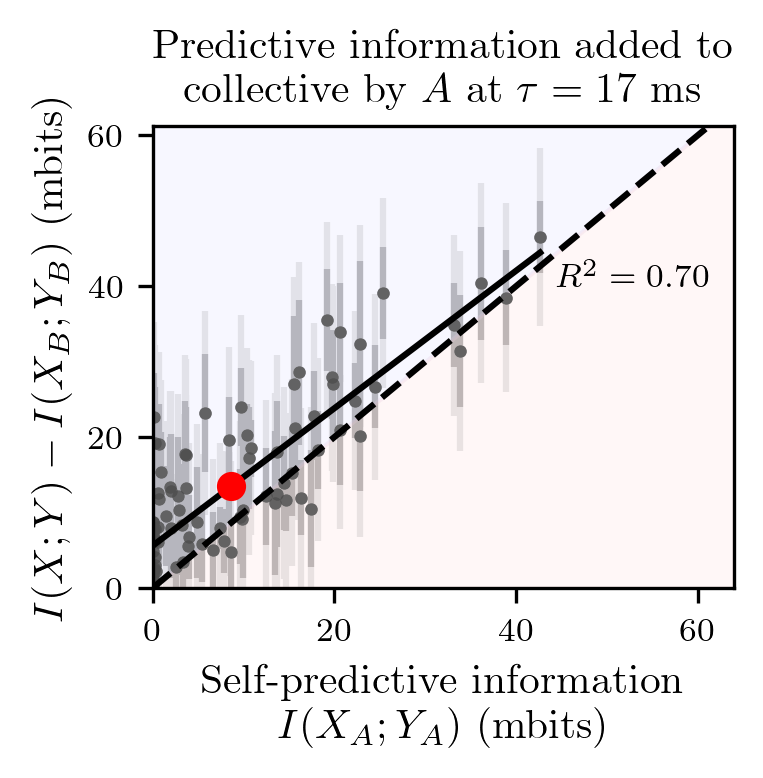

In [35]:
x = single_info[data.sort_by_info_inds] / np.log(2)
y = (averages_test_whole - averages_test_part) / np.log(2)
y_avg = np.mean(y, axis=-1)
y_group_max = np.max(y, axis=1)
y_precision_err = np.sqrt(stdevs_test_whole**2 + stdevs_test_part**2) / np.log(2)
# y_precision_err = np.sqrt(stdevs_test_part**2) / np.log(2)
y[y<0] = 0
fit = als.linear_regress(x, y_avg)
dt = 1000/60

fig, ax = plt.subplots(figsize=[2.5, 2], dpi=300)
max_x = np.max(x)
max_y = np.max(y)
max_both = max(max_x, max_y)
# ax.errorbar(x, y, yerr=yerr, marker='o', linestyle='')
# ax.plot(x * 1000, y * 1000, marker='.', linestyle='', color=(0.7,0.8,0.9,0.3), markeredgecolor='none')
ax.plot(x * 1000, y_avg * 1000, marker='.', linestyle='', color=(0.3,0.3,0.3,0.8), markeredgecolor='none')
# ax.plot(x * 1000, y_group_max * 1000, marker='.', linestyle='', color=(0.3,0.3,1,0.3), markeredgecolor='none')
ax.plot(x * 1000, fit['fit'](x) * 1000, color=(0,0,0))
ax.plot([0, max_both * 1.1 * 1000], [0, max_both * 1.1 * 1000], color='k', linestyle='--')
# ax.plot([0, max_x * 1.2 * 0.7], [0, max_y * 1.2])
mx = np.mean(x)
my = np.mean(y_avg)
y_group_spread = np.sqrt(tools.cov_entrywise(y, sum_axes=1))
yerr = np.sqrt(y_group_spread**2 + np.mean(y_precision_err**2, axis=1))
# yerr = np.sqrt(tools.cov_entrywise(y, sum_axes=1))
ax.errorbar(x * 1000, y_avg * 1000, yerr=yerr * 1000, marker='.', color=(0.9,0.9,0.9), markeredgecolor='none', linestyle='', zorder=0)
# ax.errorbar(x * 1000, y_avg * 1000, yerr=y_group_spread * 1000, marker='.', color=(0.7,0.7,0.7), markeredgecolor='none', linestyle='', zorder=0)
# ax.plot([0, mx * 1.2], [0, my * 1.2])


ax.text(max_x*1.04 * 1000, fit['fit'](max_x)*0.9* 1000, f"$R^2 = {fit['R_squared']:.2f}$")
ax.plot(mx * 1000, my* 1000, 'o', color=(1,0,0))
ax.set_xlim(0, max_x*1.5 * 1000)
# ax.set_xlim(0, max_both*0.1)
# ax.set_xlim(0, 0.01)
ax.set_ylim(0, max_both*1.1* 1000)



a = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.fill_between([0, a], [0, a], [a, a], color=(0.8,0.8,1,0.15))
ax.fill_between([0, a], [0, a], [0, 0], color=(1,0.8,0.8,0.15))
# ax.fill_between(0, max_x*1.5 * 1000)

# ax.set_xlabel('Self-predictive information \n $I(\sigma_{N,t}; \sigma_{N,t+\\tau})$ (bits)')
ax.set_xlabel('Self-predictive information \n $I(X_A;Y_A)$ (mbits)')
# ax.set_ylabel(r'$I(\sigma_{1:N,t}; \sigma_{1:N,t+\tau}) - I(\sigma_{1:N-1,t}; \sigma_{1:N-1,t+\tau})$')
# ax.set_title(f"Prediction synergy at $\\tau={tau*dt:.0f}$ ms")
ax.set_title(f" Predictive information added to\n collective by $A$ at $\\tau={tau*dt:.0f}$ ms")
# ax.set_ylabel('Predictive information added to \n collective $A\cup B$ by $A$ (mbits)')
ax.set_ylabel('$I(X;Y) - I(X_B;Y_B)$ (mbits)')
# ax.set_ylabel('Contribution $\delta_A I(X;Y)$ (mbits)')
# plt.savefig(f'./plots/single neuron synergy tau={tau}.png', dpi=3000)
# plt.savefig(f'./plots/single neuron synergy tau={tau}.svg')